# 10 · A look-up table upscaler: memory instead of arithmetic

Every model so far computes its answer. This one **looks it up**. A network that only ever sees
four pixels can only be asked so many questions - sampled at every 16th 8-bit value, 17⁴ =
83,521 of them - so after training it answers all of them once, the answers are stored, and the
network is thrown away. Running the model is then: read four pixels, find the cell of the table
they fall in, read five of its corners, and mix them. This is SR-LUT (Jo and Kim, CVPR 2021)
and MuLUT (Li et al., ECCV 2022), on this project's data and in this project's frame.

    LR luma ──► 4 taps, each kernel in 4 rotations ──► look-up: a cell, 5 corners ──► turn back, average ──► HR luma correction
                                                       (a table per kernel: megabytes)
    colour, and the rest of luma: bicubic, as in notebook 7

- **The table is what ships.** 17 points along each tap: every 16th 8-bit value, so a pixel's
  top four bits pick the cell and its bottom four say where in it. One kernel at x2 is 83,521
  rows of 4 sub-pixels - 1.3 MB in float32, 0.67 MB in float16, twenty times the whole of
  notebook 7's graph - and what it costs to run is a few dozen operations per look-up.
- **Five corners, not sixteen.** Simplex interpolation: the order of the four fractions picks
  one of the 24 simplices a 4D cell is cut into, and its five corners are mixed by differences
  of the sorted fractions. It is exact for anything linear in the taps (checked below) and
  continuous from one cell to the next.
- **Rotations widen what one table sees.** A kernel reads four pixels; turned four ways around
  the pixel it answers for, with the same table each time, it covers more - and the model
  turns with its input, exactly (checked). Three kernels (MuLUT's S, D and Y) cover 5x5 for
  three tables, and a second stage on the first one's output 9x9 - the patches' halo of 4.
- **It starts as bicubic**, like every model here: the network's last layer starts at zero,
  and it corrects luma only, as in notebook 7.
- **The address is integer arithmetic.** float16 counts integers only to 2,048, so a row of
  83,521 is found as two numbers under 289, each exact in half precision, that meet in int32.
  Everything else the look-up has to work out - which order, which corners, what weights - is
  small fixed convolutions of small integers.

Steps:

1. **Data** - the patch set, and what each validation patch shows.
2. **Model** - the network, the tables, and the checks that the look-up is exact.
3. **Speed** - counted from the exported graphs, as a graph and as one fused shader, against
   notebook 7's model and the networks the tables replace.
4. **Train** - each network as itself (the smallest at three seeds, which is the ruler), into
   tables at three sizes, then fine-tuned as tables; results overall, by content, how much of
   each table pictures read, and pictures.
5. **Save** - the best table, and check it loads back the same.
6. **Export** - the best table, and the one-table model as the cheapest tier, at the client's
   tile.

Needs: `00_data_preprocess.ipynb`. Writes `checkpoints/upscale_lut.pt` (the best) and each
run's training to `checkpoints/lut_runs/`.

In [2]:
"""Settings."""

import math

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Subset

from helpers import metrics, models, patches, speed, tiles, training, webexport
from helpers.training import DATA_DIR, DEVICE

CHECKPOINT = training.CHECKPOINT_DIR / "upscale_lut.pt"     # the best table, as it ships
RUN_DIR = training.CHECKPOINT_DIR / "lut_runs"              # each run's training, saved every epoch
SPEED_DIR = training.CHECKPOINT_DIR / "speed"               # graphs exported only to be counted
BEFORE = training.CHECKPOINT_DIR / "upscale_strategies.pt"  # notebook 4's luma model: the one to beat

LADDER = {"S": ("S", 1), "SDY": ("SDY", 1), "SDY x2": ("SDY", 2)}   # name -> (kernels, stages)
WIDTH, DEPTH = 64, 4       # the network that fills a table: 4 taps -> 4 layers of 64 -> its answers
LEVELS = 17                # table points along each tap: every 16th 8-bit value (SR-LUT's)
SWEEP_LEVELS = (9, 17, 33) # every 32nd, 16th and 8th value: what memory buys
MAX_EPOCHS = 500           # a safety limit; each training stops by itself once it has converged
BATCH_SIZE = 32
LEARNING_RATE = 1e-3       # the networks
TABLE_LEARNING_RATE = 1e-4 # the tables' own entries, fine-tuned (MuLUT's)
SEEDS = (0, 1, 2)          # the smallest network trained three times: how far luck alone moves it

STEP_WIDTH, STEP_HEIGHT = 320, 180       # LR pixels one client tile adds to the picture (notebook 5)
FRAME_WIDTH, FRAME_HEIGHT = 1920, 1080   # the whole-frame graph
ESTIMATE_ON = {"Iris Xe": "Intel Iris Xe, 96 EU (laptop iGPU)", "GTX 1650": "NVIDIA GTX 1650",
               "RTX 3060": "NVIDIA RTX 3060"}

training.seed_everything(SEEDS[0])

## 1. Data

The patch set of `00_data_preprocess.ipynb` - photos, videos and drawn desktop screens through
the stream's degradation - as notebooks 8 and 9 see it, with results split by what a patch
shows: four pixels say less about a photo than about a line of text.

In [3]:
manifest = training.load_manifest()
training.describe(manifest)
SCALE = manifest["scale"]
train_loader, val_loader = training.loaders(DATA_DIR, manifest, BATCH_SIZE, val_batch_size=128)
trim = training.trimmer(manifest)


def content(source):
    """What a source shows: a drawn desktop screen, a photo (as a moving clip) or a video."""
    if source["dataset"] == "screens":
        return "screen"
    return "photo" if "motion" in source else "video"


by_content = {}   # what a patch shows -> [validation patch indices]
for source in manifest["splits"]["val"]["sources"]:
    first, end = source["patches"]
    by_content.setdefault(content(source), []).extend(range(first, end))
print("val by content: " + ", ".join(f"{name} {len(indices):,}" for name, indices in by_content.items()))

device  cuda NVIDIA GeForce RTX 3090
scale   2
patch   72 px LR in (64 px + a halo of 4) -> 128 px HR out, 8 frames each
train  17140 patches from 1089 sources
val     3523 patches from 225 sources
val by content: photo 784, video 1,585, screen 1,154


## 2. Model

The network and the table share everything but the middle:

- **Taps.** Luma (BT.709, a frozen 1x1 convolution), then, per stage, a frozen convolution that
  copies each kernel's four taps in each of four rotations - a *group* - into four channels. The
  kernels are MuLUT's: **S**, a 2x2 square from the pixel (SR-LUT's only kernel); **D**, the same
  square dilated; **Y**, the pixel and three around its diagonal neighbour. A rotation turns the
  taps around the pixel itself, so S covers 3x3 and D and Y 5x5.
- **Answers.** The *network* answers a group with a small MLP per kernel and stage - 1x1
  convolutions, 4 -> 64 -> 64 -> 64 -> 64 -> its answers - the same in every rotation. The *table*
  holds that MLP's answers at `LEVELS` points along each tap and interpolates between them.
- **Adding up.** In the last stage a group answers the pixel's four x2 sub-pixels as its rotated
  kernel saw them; a frozen 1x1 convolution turns each back, averages the rotations and adds
  the kernels. That is luma's correction, added to R, G and B over bicubic, as in notebook 7.
- **Stages.** An earlier stage answers one number per group, a correction of the LR luma the
  next stage reads. Two stages of SDY reach 4 px, the patches' halo.

The look-up:

- **Where a point is.** Table coordinates are luma in steps of 16/255, so an 8-bit value's top
  four bits are its cell and the bottom four its place in it, and the 17th point (256/255) is
  never reached. `floor` is the cell's lowest corner; the four fractions say where in the cell.
- **Five corners.** Stepping along the taps from the largest fraction to the smallest visits
  the five corners of the simplex the point lies in. Corner k's weight is the k-th largest
  fraction minus the next one (with 1 before the first and 0 after the last). A tie can go
  either way, since both ways give the same value; here it goes to the earlier tap.
- **Bookkeeping as fixed convolutions.** The order is a rank per tap - how many of the other
  three come before it, from six pairwise comparisons - and corner k has stepped along a tap
  once that tap's rank is below k. Differences, ranks, addresses and weights are each a small
  fixed convolution per group, and every value in them but the weights is a small integer,
  exact in float16.
- **An integer address.** A corner's row is two numbers under 289 = 17²: hi from taps 0 and 1,
  lo from taps 2 and 3. They meet in int32 - row = 289 hi + lo, plus where the kernel's table
  starts - and one `Gather` per stage reads every corner of every group.

Untrained, the network's last layer is zero, so the network - and the table it fills - is
bicubic, exactly.

In [4]:
LUMA = torch.tensor(models.LUMA_709)
ROTATIONS = 4
KERNELS = {   # a kernel's four taps, (down, across) from the pixel it answers for
    "S": ((0, 0), (0, 1), (1, 0), (1, 1)),   # SR-LUT's 2x2 square
    "D": ((0, 0), (0, 2), (2, 0), (2, 2)),   # MuLUT: the square, dilated
    "Y": ((0, 0), (1, 1), (1, 2), (2, 1)),   # MuLUT: the diagonal neighbour and two beside it
}
PAIRS = [(i, j) for i in range(4) for j in range(i + 1, 4)]   # the six pairs a sort of four compares


def rotate(offset, turns):
    """An offset (down, across) turned by `turns` quarter turns."""
    dy, dx = offset
    for _ in range(turns):
        dy, dx = dx, -dy
    return dy, dx


def frozen(conv, weight, bias=None):
    """`conv` with these weights (and bias), never trained."""
    with torch.no_grad():
        conv.weight.copy_(weight.reshape(conv.weight.shape))
        if bias is not None:
            conv.bias.copy_(bias)
    for parameter in conv.parameters():
        parameter.requires_grad_(False)
    return conv


def per_group(groups, matrix, bias=None):
    """A frozen 1x1 convolution applying one small matrix (out x in) to every group of channels."""
    out, inputs = matrix.shape
    conv = nn.Conv2d(groups * inputs, groups * out, 1, groups=groups, bias=bias is not None)
    return frozen(conv, matrix.repeat(groups, 1), None if bias is None else bias.repeat(groups))


class FourTapUpscaler(models.Upscaler):
    """Bicubic colour, and luma corrected by stages that each answer from four pixels at a time.

    A stage reads every kernel's four taps in each of four rotations (a group), answers every
    group (`answer`, which a subclass implements) and adds the answers up. Every stage but the
    last corrects the LR luma the next one reads; the last makes the HR luma correction.
    """

    def __init__(self, kernels="S", stages=1, scale=2):
        super().__init__(scale, skip=5)
        self.kernels, self.stages = kernels, stages
        self.groups = len(kernels) * ROTATIONS
        self.outs = [1] * (stages - 1) + [scale * scale]   # what a group answers, per stage
        reach = max(abs(v) for name in kernels for tap in KERNELS[name] for v in tap)
        self.halo = max(stages * reach, self.skip_size // 2)
        self.to_luma = frozen(nn.Conv2d(3, 1, 1, bias=False), LUMA)

        size, centre = 2 * reach + 1, (scale - 1) / 2
        self.reads, self.combines = nn.ModuleList(), nn.ModuleList()
        for out in self.outs:
            # read: channel g * 4 + t is tap t of group g = kernel * ROTATIONS + rotation
            read = torch.zeros(self.groups * 4, 1, size, size)
            for k, name in enumerate(kernels):
                for r in range(ROTATIONS):
                    for t, tap in enumerate(KERNELS[name]):
                        dy, dx = rotate(tap, r)
                        read[(k * ROTATIONS + r) * 4 + t, 0, reach + dy, reach + dx] = 1
            self.reads.append(frozen(nn.Conv2d(1, self.groups * 4, size, padding=reach, bias=False), read))
            # combine: a group's answer o is the sub-pixel o turned by its rotation; rotations are
            # averaged and kernels added
            combine = torch.zeros(out, self.groups * out)
            for g in range(self.groups):
                for o in range(out):
                    dy, dx = rotate((o // scale - centre, o % scale - centre), g % ROTATIONS)
                    to = round(dy + centre) * scale + round(dx + centre) if out > 1 else 0
                    combine[to, g * out + o] = 1 / ROTATIONS
            self.combines.append(frozen(nn.Conv2d(self.groups * out, out, 1, bias=False), combine))

    def answer(self, stage, taps):
        """(N, groups * 4, H, W) taps -> (N, groups * outs[stage], H, W) answers."""
        raise NotImplementedError

    def residual(self, x):
        luma = self.to_luma(x)
        for stage in range(self.stages):
            correction = self.combines[stage](self.answer(stage, self.reads[stage](luma)))
            if stage < self.stages - 1:
                luma = (luma + correction).clamp(0, 1)
        return torch.cat([correction, correction, correction], dim=1)   # on every colour: Y moves


class FourTapNet(FourTapUpscaler):
    """The network that fills the tables: per stage and kernel, an MLP from four taps to a
    group's answers, the same in every rotation. Its last layer starts at zero: bicubic."""

    def __init__(self, kernels="S", stages=1, width=WIDTH, depth=DEPTH, scale=2):
        super().__init__(kernels, stages, scale)
        self.width, self.depth = width, depth
        self.nets = nn.ModuleList()
        for out in self.outs:
            bank = nn.ModuleList()
            for _ in kernels:
                layers, channels = [], 4
                for _ in range(depth):
                    layers += [nn.Conv2d(channels, width, 1), nn.ReLU(inplace=True)]
                    channels = width
                bank.append(nn.Sequential(*layers, models.zero_start(nn.Conv2d(channels, out, 1))))
            self.nets.append(bank)

    def answer(self, stage, taps):
        n, _, h, w = taps.shape
        taps = taps.view(n, len(self.kernels), ROTATIONS * 4, h, w)
        return torch.cat([net(taps[:, k].reshape(n * ROTATIONS, 4, h, w)).view(n, -1, h, w)   # rotations as more pictures
                          for k, net in enumerate(self.nets[stage])], dim=1)


class LutUpscaler(FourTapUpscaler):
    """The same model with every MLP replaced by a table of its answers, `levels` points along
    each tap, read by simplex interpolation. The tables are its only parameters."""

    def __init__(self, kernels="S", stages=1, levels=LEVELS, scale=2):
        super().__init__(kernels, stages, scale)
        L, G = levels, self.groups
        self.levels = levels
        self.spacing = 256 // (levels - 1) / 255   # luma from one table point to the next: 16 / 255 at 17
        for read in self.reads:                     # read table coordinates rather than luma
            read.weight.data /= self.spacing
        self.tables = nn.ParameterList(nn.Parameter(torch.zeros(len(kernels) * L ** 4, out)) for out in self.outs)
        self.register_buffer("first_row", (torch.arange(G, dtype=torch.int32) // ROTATIONS * L ** 4).view(G, 1, 1, 1),
                             persistent=False)   # where each group's kernel's table starts
        self.register_buffer("corners", torch.arange(5.0).view(5, 1, 1, 1), persistent=False)

        # per group: the six differences f_i - f_j, then each tap's rank - how many taps come
        # before it, f_i >= f_j putting i before j and anything else j before i
        differ, rank, rank_bias = torch.zeros(6, 4), torch.zeros(4, 6), torch.zeros(4)
        for p, (i, j) in enumerate(PAIRS):
            differ[p, i], differ[p, j] = 1, -1
            rank[j, p] += 1
            rank[i, p] -= 1
            rank_bias[i] += 1
        # per corner k: its address (hi, lo) from its four coordinates, and S_k, the sum of the k
        # largest fractions; per group: each corner's weight, the k-th largest fraction
        # (S_k - S_k-1) minus the next, with 1 before the first and 0 after the last
        largest = torch.zeros(6, 5)
        for k in range(1, 5):
            largest[k, k], largest[k, k - 1] = 1, -1
        self.differ = per_group(G, differ)
        self.rank = per_group(G, rank, rank_bias)
        self.address = per_group(G * 5, torch.tensor([[L, 1.0, 0, 0], [0, 0, L, 1.0]]))
        self.add_up = per_group(G * 5, torch.ones(1, 4))
        self.weigh = per_group(G, largest[:5] - largest[1:], torch.tensor([1.0, 0, 0, 0, 0]))

    @torch.no_grad()
    def fill_from(self, net):
        """Every table entry becomes the network's answer at that point."""
        level = torch.arange(self.levels, device=self.tables[0].device) * self.spacing
        points = torch.cartesian_prod(level, level, level, level)   # tap 0 slowest, as the address counts
        for stage, bank in enumerate(net.nets):
            for k, mlp in enumerate(bank):
                answers = mlp(points.T[None, :, :, None])[0, :, :, 0].T
                self.tables[stage][k * self.levels ** 4:(k + 1) * self.levels ** 4] = answers
        return self

    def look_up(self, table, coordinates):
        """Simplex interpolation of `table` at (N, groups * 4, H, W) table coordinates in
        [0, levels - 1). Returns (N, groups, H, W, answers)."""
        n, _, h, w = coordinates.shape
        G = self.groups
        base = coordinates.floor()                                       # the cell's lowest corner
        fraction = coordinates - base                                    # where in the cell
        ahead = (self.differ(fraction) >= 0).to(fraction.dtype)          # f_i >= f_j, for each pair i < j
        rank = self.rank(ahead).view(n, G, 1, 4, h, w)                   # how many taps come before tap j
        stepped = (rank < self.corners).to(fraction.dtype)               # (N, G, 5, 4, H, W): corner k has stepped along j
        corner = (base.view(n, G, 1, 4, h, w) + stepped).view(n, G * 20, h, w)
        hi, lo = self.address(corner).view(n, G, 5, 2, h, w).unbind(3)   # each under 289: exact in float16
        row = hi.to(torch.int32) * self.levels ** 2 + lo.to(torch.int32) + self.first_row
        largest = self.add_up((fraction.view(n, G, 1, 4, h, w) * stepped).view(n, G * 20, h, w))
        weight = self.weigh(largest).view(n, G, 5, h, w)                 # adds up to 1
        values = table.index_select(0, row.flatten()).view(n, G, 5, h, w, -1)
        return (values * weight[..., None]).sum(dim=2)

    def answer(self, stage, taps):
        n, _, h, w = taps.shape
        coordinates = taps.clamp(0, self.levels - 1 - 2 ** -6)   # an 8-bit picture never reaches the top
        return self.look_up(self.tables[stage], coordinates).permute(0, 1, 4, 2, 3).reshape(n, -1, h, w)

In [5]:
"""Checks: untrained, every network and table is bicubic; both turn with their input; a table
matches its network on its grid, and gives anything linear back exactly."""

models.check_skip_is_bicubic(SCALE)
probe_lr = next(iter(val_loader))[0][:8].to(DEVICE)
picture = torch.rand(2, 3, 40, 40, device=DEVICE)


@torch.no_grad()
def scrambled(net, seed=0):
    """`net` with every learned weight random, its last layers too, so a check sees more than bicubic."""
    torch.manual_seed(seed)
    for parameter in net.parameters():
        if parameter.requires_grad:
            parameter.normal_(0, 0.3)
    return net


def turned(model, x):
    """How far `model` is from turning with its input: a quarter turn in, against its output turned."""
    return (model(torch.rot90(x, 1, (2, 3))) - torch.rot90(model(x), 1, (2, 3))).abs().max().item()


gaps = {}
with torch.no_grad(), training.full_precision():
    bicubic = trim(models.bicubic(probe_lr, SCALE))
    for name, (kernels, stages) in LADDER.items():
        net = FourTapNet(kernels, stages).to(DEVICE)
        assert net.halo <= manifest["halo"], f"{name} reaches further than the patches' halo"
        table = LutUpscaler(kernels, stages).to(DEVICE).fill_from(net)
        gaps[f"{name}: untrained network against bicubic"] = (trim(net(probe_lr)) - bicubic).abs().max().item()
        gaps[f"{name}: its table against bicubic"] = (trim(table(probe_lr)) - bicubic).abs().max().item()
        table.fill_from(scrambled(net))
        gaps[f"{name}: network, turned"] = turned(net, picture)
        gaps[f"{name}: table, turned"] = turned(table, picture)
        if stages == 1:   # a second stage reads the first one's output, which is on no grid
            greys = (torch.randint(0, LEVELS - 1, (2, 1, 40, 40), device=DEVICE) * table.spacing).expand(-1, 3, -1, -1)
            gaps[f"{name}: table against network, on its grid"] = (table(greys) - net(greys)).abs().max().item()

    # a table of anything linear in the taps gives it back exactly, between the points too - and on ties
    table = LutUpscaler("SDY").to(DEVICE)
    level = torch.arange(LEVELS, dtype=torch.float32, device=DEVICE)
    slopes, offsets = torch.randn(3, 4, 4, device=DEVICE), torch.randn(3, 4, device=DEVICE)   # per kernel
    grid = torch.cartesian_prod(level, level, level, level)
    table.tables[0].copy_(torch.cat([grid @ slopes[k] + offsets[k] for k in range(3)]))
    kernel = torch.arange(table.groups, device=DEVICE) // ROTATIONS
    anywhere = torch.rand(2, table.groups * 4, 10, 10, device=DEVICE) * (LEVELS - 1.01)
    on_ties = (torch.randint(0, LEVELS - 1, anywhere.shape, device=DEVICE)
               + torch.randint(0, 3, anywhere.shape, device=DEVICE) / 4)   # fractions of 0, 1/4 and 1/2
    for label, points in {"anywhere": anywhere, "on ties": on_ties}.items():
        linear = (torch.einsum("ngjhw,gjo->nghwo", points.view(2, table.groups, 4, 10, 10), slopes[kernel])
                  + offsets[kernel][None, :, None, None])
        relative = (table.look_up(table.tables[0], points) - linear).abs().max() / linear.abs().max()
        gaps[f"a linear table, {label} (relative)"] = relative.item()

for name, gap in gaps.items():
    assert gap < 1e-5, f"{name}: {gap:.1e}"
print("exact, to float32 rounding:")
for name, gap in gaps.items():
    print(f"  {name:<44}{gap:.0e}")
print()
for name, (kernels, stages) in LADDER.items():
    net, table = FourTapNet(kernels, stages), LutUpscaler(kernels, stages)
    entries = models.count_parameters(table, True)
    print(f"{name:<8} halo {net.halo}   network {models.count_parameters(net, True):7,} learned parameters   "
          f"table {entries:9,} entries: {entries * 4 / 1e6:4.1f} MB in float32, {entries * 2 / 1e6:4.1f} MB in float16")

exact, to float32 rounding:
  S: untrained network against bicubic        4e-07
  S: its table against bicubic                4e-07
  S: network, turned                          5e-07
  S: table, turned                            7e-07
  S: table against network, on its grid       0e+00
  SDY: untrained network against bicubic      4e-07
  SDY: its table against bicubic              4e-07
  SDY: network, turned                        2e-06
  SDY: table, turned                          2e-06
  SDY: table against network, on its grid     0e+00
  SDY x2: untrained network against bicubic   4e-07
  SDY x2: its table against bicubic           4e-07
  SDY x2: network, turned                     1e-06
  SDY x2: table, turned                       1e-06
  a linear table, anywhere (relative)         2e-07
  a linear table, on ties (relative)          1e-07

S        halo 2   network  13,060 learned parameters   table   334,084 entries:  1.3 MB in float32,  0.7 MB in float16
SDY      halo 2   ne

## 3. Speed

Counted the way notebooks 3, 4, 8 and 9 count: operations and memory traffic in the exported
ONNX graph at the client's tile, per LR pixel, and the roofline estimate for a 1080p frame, at
the share of its peak this computer's GPU reaches on notebook 7's model in torch. The networks
are counted too: they are what each table replaces. The graphs are untrained - the work does
not depend on the weights.

Two things are new here:

- **The table is a weight.** The estimate reads every weight once per run, so a table's
  megabytes are charged per tile, though a run reads only the rows it gathers.
- **A graph is not how a table wants to run.** Each operator writes its output to memory and
  the next reads it back, and a look-up is a dozen small operators on a few channels each - so
  a table moves far more bytes as a graph than it computes. The **fused** rows count the same
  operations with the traffic of one shader that reads the tile, writes the picture and keeps
  everything between in registers: what a table costs run as what it is.

Besides `Conv`, `Add`, `Concat` and `DepthToSpace`, a table's graph needs `Floor`, `Clip`, a
comparison (`GreaterOrEqual`, `Less`), `Cast` to and from integers, integer `Mul` and `Add`,
and the `Gather` that reads the table, which is the idea itself. All are outside the budget the
browser has been measured on.

In [6]:
plan = tiles.plan_tiling((FRAME_WIDTH, FRAME_HEIGHT), scale=SCALE, halo=manifest["halo"])
tile_input = plan["input"][2:]
frame_lr = torch.rand(1, 3, FRAME_HEIGHT // SCALE, FRAME_WIDTH // SCALE, device=DEVICE)
FUSED_BYTES = (3 + 3 * SCALE ** 2) * 4   # per LR pixel: read its RGB, write its sub-pixels' RGB (float32)


def at_frame(ops, bytes_, weight_bytes):
    """The work of a 1080p frame cut into the client's tiles, from per-LR-pixel costs."""
    computed = plan["runs"] * tile_input[0] * tile_input[1]
    return {"operations": computed * ops, "bytes": computed * bytes_ + plan["runs"] * weight_bytes}


def cost(model, name):
    """Operations and bytes per LR pixel of a model's graph at the client's tile, its weights'
    bytes, and the milliseconds of a 1080p frame through it in torch on this computer."""
    model = model.to(DEVICE).eval()
    graph = webexport.export(model, f"speed_check_{name}.onnx", tile_input, halo=model.halo, models_dir=SPEED_DIR)
    work = webexport.count_work(graph["path"])
    ops, bytes_ = work["operations"] / work["input_pixels"], work["activation_bytes"] / work["input_pixels"]
    with torch.no_grad():
        measured_ms = speed.time_ms(lambda: model(frame_lr), seconds=1.0)
    return {"ops": ops, "bytes": bytes_, "weight_bytes": work["weight_bytes"], "measured_ms": measured_ms,
            "frame": at_frame(ops, bytes_, work["weight_bytes"]), "graph": graph}


costs = {"notebook 7": cost(models.LumaUpscaler((24,), 2, 3, scale=SCALE), "luma_24x2")}
for name, (kernels, stages) in LADDER.items():
    tag = name.replace(" ", "")
    costs[f"{name} network"] = cost(FourTapNet(kernels, stages), f"lut_net_{tag}")
    costs[f"{name} table"] = table = cost(LutUpscaler(kernels, stages), f"lut_{tag}")
    costs[f"{name} table, fused"] = {**table, "bytes": FUSED_BYTES, "graph": None,
                                     "frame": at_frame(table["ops"], FUSED_BYTES, table["weight_bytes"])}

reference = costs["notebook 7"]
whole = {"operations": frame_lr[0, 0].numel() * reference["ops"],
         "bytes": frame_lr[0, 0].numel() * reference["bytes"] + reference["weight_bytes"]}
efficiency = (speed.roofline_ms(whole, *speed.HARDWARE[speed.THIS_GPU])[0] / reference["measured_ms"]
              if DEVICE.type == "cuda" else 1.0)
print(f"estimates at {efficiency:.0%} of each device's peak (notebook 7's model here)\n")
print(f"{'':<20}{'ops / LR px':>12}{'bytes / LR px':>15}{'weights, MB':>13}{'here, ms':>10}"
      + "".join(f"{short + ', ms':>14}" for short in ESTIMATE_ON))
for name, c in costs.items():
    estimates = [speed.roofline_ms(c["frame"], *speed.HARDWARE[device]) for device in ESTIMATE_ON.values()]
    here = f"{c['measured_ms']:10.2f}" if c["graph"] is not None else f"{'-':>10}"
    print(f"{name:<20}{c['ops']:12,.0f}{c['bytes']:15,.0f}{c['weight_bytes'] / 1e6:13.2f}{here}"
          + "".join(f"{ms / efficiency:7.1f} ({limit[0]})".rjust(14) for ms, limit in estimates))
print("\n(c) compute-bound, (m) memory-bound; a fused row is the table above it, run as one shader")
for c in costs.values():
    if c["graph"] is not None:
        print(webexport.summary_line(c["graph"]))

estimates at 44% of each device's peak (notebook 7's model here)

                     ops / LR px  bytes / LR px  weights, MB  here, ms   Iris Xe, ms  GTX 1650, ms  RTX 3060, ms
notebook 7                28,120          2,536         0.06      3.22      47.4 (m)      25.2 (m)       9.0 (m)
S network                106,698         17,328         0.06     15.65     323.9 (m)     172.1 (m)      61.2 (m)
S table                    3,850          5,696         1.34     12.04     106.9 (m)      56.8 (m)      20.2 (m)
S table, fused             3,850             60         1.34         -       2.4 (c)       1.6 (c)       0.4 (c)
SDY network              317,994         51,504         0.16     46.13     962.6 (m)     511.4 (m)     181.8 (m)
SDY table                  9,450         16,224         4.03     34.59     304.4 (m)     161.7 (m)      57.5 (m)
SDY table, fused           9,450             60         4.03         -       6.0 (c)       4.0 (c)       0.9 (c)
SDY x2 network           629,1

## 4. Train

The recipe of notebooks 2 to 9: Adam from 1e-3, batch 32, `metrics.ssim_l1_loss`, the epoch
with the best luma SSIM kept, each run trained until it has converged. A network trains as
itself - on continuous taps, no table anywhere - and only becomes a table below. `S` is
trained at three seeds - their spread is what luck alone moves a score - and `SDY` and
`SDY x2` at one.

Each run saves its training to `checkpoints/lut_runs/` after every epoch: run the cell again
after an interruption and it carries on; finished runs just load.

In [7]:
def network_key(name):
    """A network's name below: S is trained at three seeds, and its seed 0 stands for it."""
    return f"{name} network" + (f", seed {SEEDS[0]}" if name == "S" else "")


def train_network(name, seed=0):
    """Train a fresh network, or load its saved training. Returns it at its best epoch, its
    history and its best epoch."""
    kernels, stages = LADDER[name]
    torch.manual_seed(seed)
    model = FourTapNet(kernels, stages).to(DEVICE)
    torch.manual_seed(seed)   # the same batches in the same order, whatever the model
    run = f"net_{name.replace(' ', '')}_seed{seed}"
    history, best = training.train(model, train_loader, val_loader, trim, MAX_EPOCHS, learning_rate=LEARNING_RATE,
                                   loss_fn=metrics.ssim_l1_loss, select="ssim", checkpoint=RUN_DIR / f"{run}.pt",
                                   verbose=0)
    print(f"{run:<20} best epoch {best['epoch']:3} of {len(history):3}, ssim-y {best['score']:.4f}")
    return model, history, best


networks, histories, bests = {}, {}, {}
for seed in SEEDS:
    key = f"S network, seed {seed}"
    networks[key], histories[key], bests[key] = train_network("S", seed)
for name in list(LADDER)[1:]:
    key = network_key(name)
    networks[key], histories[key], bests[key] = train_network(name)

net_S_seed0          best epoch  67 of  97, ssim-y 0.9272
net_S_seed1          best epoch  84 of 108, ssim-y 0.9270
net_S_seed2          best epoch  93 of  99, ssim-y 0.9269
net_SDY_seed0        best epoch  96 of 108, ssim-y 0.9312
net_SDYx2_seed0      best epoch  90 of 108, ssim-y 0.9342


### Into tables

**Filling.** Every entry of a table becomes its network's answer at that point, and the network
is not used again. Between the points the table is linear, so what filling loses is how far the
network bends between two of them - and in a second stage, also the first stage's error, which
the second one reads.

**What memory buys.** Each network filled at 9, 17 and 33 points along each tap - every 32nd,
16th and 8th 8-bit value. Each step up is twice the points along each of four taps: sixteen
times the table.

In [8]:
def filled(name, levels=LEVELS):
    """The table of a network on the ladder (seed 0), at `levels` points along each tap."""
    kernels, stages = LADDER[name]
    return LutUpscaler(kernels, stages, levels).to(DEVICE).fill_from(networks[network_key(name)]).eval()


sweep = {}
for name in LADDER:
    for levels in SWEEP_LEVELS:
        table = filled(name, levels)
        sweep[name, levels] = {"scores": training.evaluate(table, val_loader, trim),
                               "MB": models.count_parameters(table, True) * 2 / 1e6}   # in float16
        del table

print("luma SSIM of each table; under it, its loss against its network and its size in float16\n")
print(f"{'':<10}{'network':>10}" + "".join(f"{f'{levels} points':>20}" for levels in SWEEP_LEVELS))
for name in LADDER:
    network = bests[network_key(name)]["score"]
    print(f"{name:<10}{network:10.4f}" + "".join(f"{sweep[name, levels]['scores']['ssim']:20.4f}" for levels in SWEEP_LEVELS))
    print(f"{'':<20}" + "".join(f"{sweep[name, levels]['scores']['ssim'] - network:+.4f}, {sweep[name, levels]['MB']:6.1f} MB".rjust(20)
                                for levels in SWEEP_LEVELS))

luma SSIM of each table; under it, its loss against its network and its size in float16

             network            9 points           17 points           33 points
S             0.9272              0.9192              0.9221              0.9263
                      -0.0080,    0.1 MB  -0.0051,    0.7 MB  -0.0009,    9.5 MB
SDY           0.9312              0.9193              0.9262              0.9297
                      -0.0119,    0.2 MB  -0.0051,    2.0 MB  -0.0016,   28.5 MB
SDY x2        0.9342              0.9189              0.9319              0.9338
                      -0.0153,    0.2 MB  -0.0023,    2.5 MB  -0.0004,   35.6 MB


### Fine-tuning the tables

MuLUT's LUT-aware fine-tuning. The entries are the
parameters: the loss reaches each one through the interpolation weights of the pixels that read
it, and the same recipe trains them, from the filled table and at 1e-4. A run starts as its
filled table exactly, so whatever it gains is the table learning what its network could not
hand it - the bends between points, and in two stages, what the first stage's table really
answers. Retraining a network means deleting its table's run in `checkpoints/lut_runs/` too.

In [9]:
tuned, table_histories, table_bests = {}, {}, {}
for name in LADDER:
    table = filled(name).train()
    run = f"table_{name.replace(' ', '')}"
    table_histories[name], table_bests[name] = training.train(
        table, train_loader, val_loader, trim, MAX_EPOCHS, learning_rate=TABLE_LEARNING_RATE,
        loss_fn=metrics.ssim_l1_loss, select="ssim", checkpoint=RUN_DIR / f"{run}.pt", verbose=0)
    tuned[name] = table.eval()
    print(f"{run:<20} best epoch {table_bests[name]['epoch']:3} of {len(table_histories[name]):3}, "
          f"ssim-y {table_bests[name]['score']:.4f}")

# notebook 4's winner, the same body as notebook 7's: the model to beat
before = training.load_checkpoint(BEFORE)
notebook4 = getattr(models, before["architecture"])(scale=SCALE, **before["arguments"]).to(DEVICE)
notebook4.load_state_dict(before["state_dict"])
print(f"notebook 4's model: its {before['strategy']}, loaded")

table_S              best epoch  45 of  69, ssim-y 0.9251
table_SDY            best epoch  38 of  62, ssim-y 0.9286
table_SDYx2          best epoch  23 of  65, ssim-y 0.9343
notebook 4's model: its luma 24 + 2 blocks, loaded


### The result

Every model on the whole validation set - the 128 px cores, as every notebook scores - with the
operations its graph takes per LR pixel and what it ships, in float16. **better** / **worse**
means a gap wider than the spread of the `S` network's three seeds; **luck** means this set
cannot tell the two apart.

The questions, in order: what each table loses against the network it was filled from, what
fine-tuning wins back, what each step up the ladder buys (one table seeing 3x3, three seeing
5x5, two stages seeing 9x9), and how far notebook 4's model still is.

In [10]:
BASELINES = {"bicubic": models.Resize(SCALE), "nearest": models.Resize(SCALE, "nearest")}
trained, cost_of = {}, {}   # name -> model, and the row of `costs` its graph is
for key, network in networks.items():
    trained[key], cost_of[key] = network, key.split(",")[0]   # "S network, seed 1" costs what "S network" does
for name in LADDER:
    trained[f"{name} table"], cost_of[f"{name} table"] = filled(name), f"{name} table"
for name in LADDER:
    trained[f"{name} table, fine-tuned"], cost_of[f"{name} table, fine-tuned"] = tuned[name], f"{name} table"
trained["notebook 4's model"], cost_of["notebook 4's model"] = notebook4, "notebook 7"


def score(name, indices=None):
    """`metrics.report` of one model (or baseline) on the validation patches `indices` (None: all)."""
    dataset = val_loader.dataset if indices is None else Subset(val_loader.dataset, indices)
    model = BASELINES[name] if name in BASELINES else trained[name]
    return training.evaluate(model.to(DEVICE), DataLoader(dataset, batch_size=128), trim)


def cost_columns(name, scores):
    """The last columns: operations per LR pixel of the model's graph, and its MB in float16."""
    if name in BASELINES:
        return ""
    row = costs[cost_of[name]]
    return f"{row['ops']:12,.0f}{row['weight_bytes'] / 2e6:9.2f}"


def compare(a, b, label):
    word = "luck" if abs(a - b) <= spread else ("better" if a > b else "worse")
    print(f"{label:<50}{a - b:+.4f} ssim-y  {word}")


results = {name: score(name) for name in [*BASELINES, *trained]}
seeds = [results[f"S network, seed {seed}"]["ssim"] for seed in SEEDS]
spread = max(seeds) - min(seeds)
print(f"S network at {len(SEEDS)} seeds: {spread:.4f} ssim-y apart. "
      "Last columns: operations per LR pixel, and MB in float16.")
metrics.print_table(results, extra=cost_columns)

best_name = max(LADDER, key=lambda name: results[f"{name} table, fine-tuned"]["ssim"])
print()
for name in LADDER:
    filled_ssim, tuned_ssim = results[f"{name} table"]["ssim"], results[f"{name} table, fine-tuned"]["ssim"]
    compare(filled_ssim, results[network_key(name)]["ssim"], f"{name}: its table against its network")
    compare(tuned_ssim, filled_ssim, f"{name}: fine-tuned over filled")
    compare(tuned_ssim, results["bicubic"]["ssim"], f"{name}: fine-tuned table over bicubic")
names = list(LADDER)
for smaller, larger in zip(names, names[1:]):
    compare(results[f"{larger} table, fine-tuned"]["ssim"], results[f"{smaller} table, fine-tuned"]["ssim"],
            f"{larger} over {smaller}, fine-tuned tables")
compare(results["notebook 4's model"]["ssim"], results[f"{best_name} table, fine-tuned"]["ssim"],
        f"notebook 4's model over the {best_name} table")

S network at 3 seeds: 0.0003 ssim-y apart. Last columns: operations per LR pixel, and MB in float16.
                              wpsnr   psnr-y   psnr-u   psnr-v  psnr-rgb   ssim-y
bicubic                       34.14    33.18    50.67    51.46     32.02   0.9049
nearest                       32.39    31.36    50.33    51.12     30.52   0.8887
S network, seed 0             34.69    33.75    50.69    51.49     32.46   0.9272     106,698     0.03
S network, seed 1             34.65    33.70    50.69    51.49     32.43   0.9270     106,698     0.03
S network, seed 2             34.70    33.76    50.69    51.49     32.47   0.9269     106,698     0.03
SDY network                   35.12    34.21    50.71    51.50     32.81   0.9312     317,994     0.08
SDY x2 network                35.49    34.60    50.71    51.50     33.11   0.9342     629,168     0.16
S table                       34.53    33.56    50.69    51.49     32.35   0.9221       3,850     0.67
SDY table                     34.94

### By content

The gain over bicubic on screens, photos and video apart: luma SSIM, and luma PSNR in dB.

In [11]:
SHOW = [*(f"{name} table, fine-tuned" for name in LADDER), "notebook 4's model"]
print(f"{'':<8}{'patches':>8}{'bicubic ssim-y':>16}" + "".join(f"{name:>26}" for name in SHOW))
for value, indices in by_content.items():
    base = score("bicubic", indices)
    row = f"{value:<8}{len(indices):8,}{base['ssim']:16.4f}"
    for name in SHOW:
        r = score(name, indices)
        row += f"{r['ssim'] - base['ssim']:+.4f} / {r['y'] - base['y']:+.2f}".rjust(26)
    print(row)

         patches  bicubic ssim-y       S table, fine-tuned     SDY table, fine-tuned  SDY x2 table, fine-tuned        notebook 4's model
photo        784          0.8359           +0.0116 / +0.02           +0.0145 / +0.22           +0.0167 / +0.38           +0.0217 / +0.74
video      1,585          0.9535           +0.0060 / -0.08           +0.0079 / +0.31           +0.0102 / +0.64           +0.0122 / +1.20
screen     1,154          0.8851           +0.0453 / +2.08           +0.0516 / +2.76           +0.0643 / +3.30           +0.0425 / +1.75


### How much of a table pictures read

A table spends the same memory on every combination of four values, and pictures are not
random: neighbouring pixels are mostly alike. For each fine-tuned table and kernel, the share of
its cells any validation pixel reads, and the share that holds 99% of the reads. Then, for the
`S` table, reads and cells by the *spread* of a cell - its largest coordinate minus its smallest,
in table steps - added up from 0: where the reads are against where the memory is. If nearly
every read lands at small spreads and most cells do not, most of the memory describes
neighbourhoods that do not occur, and a table kept fine near its diagonal and coarse elsewhere
would be far smaller - the idea of diagonal-first compression of these tables (Li et al., 2024).

S        stage 1  kernel S:   61.0% of the cells read at all, 99% of the reads in 15.04%
SDY      stage 1  kernel S:   61.0% of the cells read at all, 99% of the reads in 15.04%
SDY      stage 1  kernel D:   74.6% of the cells read at all, 99% of the reads in 24.72%
SDY      stage 1  kernel Y:   68.8% of the cells read at all, 99% of the reads in 22.12%
SDY x2   stage 1  kernel S:   61.0% of the cells read at all, 99% of the reads in 15.04%
SDY x2   stage 1  kernel D:   74.6% of the cells read at all, 99% of the reads in 24.72%
SDY x2   stage 1  kernel Y:   68.8% of the cells read at all, 99% of the reads in 22.12%
SDY x2   stage 2  kernel S:   62.0% of the cells read at all, 99% of the reads in 20.22%
SDY x2   stage 2  kernel D:   71.1% of the cells read at all, 99% of the reads in 27.96%
SDY x2   stage 2  kernel Y:   70.3% of the cells read at all, 99% of the reads in 29.43%


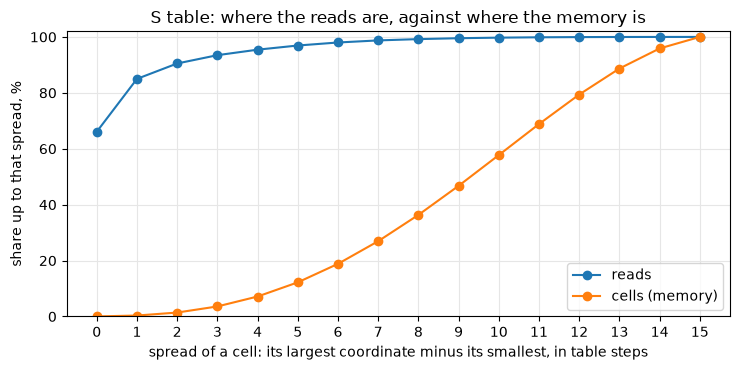

spread <= 0:  66.09% of the reads,   0.02% of the cells
spread <= 1:  85.00% of the reads,   0.34% of the cells
spread <= 2:  90.50% of the reads,   1.41% of the cells
spread <= 4:  95.44% of the reads,   7.15% of the cells


In [12]:
@torch.no_grad()
def reads(model):
    """How many times validation pixels (the cores) land in each cell of each stage's table."""
    counts = [torch.zeros(len(model.kernels) * model.levels ** 4, dtype=torch.long, device=DEVICE) for _ in model.tables]
    place = torch.tensor([model.levels ** p for p in (3, 2, 1, 0)], device=DEVICE).view(1, 1, 4, 1, 1)
    halo = manifest["halo"]
    for lr, _ in val_loader:
        luma = model.to_luma(lr.to(DEVICE))
        for stage in range(model.stages):
            taps = model.reads[stage](luma)
            cell = taps.clamp(0, model.levels - 1 - 2 ** -6).floor()[..., halo:-halo, halo:-halo]
            n, _, h, w = cell.shape
            row = (cell.view(n, model.groups, 4, h, w) * place).sum(2).long() + model.first_row.long().view(1, -1, 1, 1)
            counts[stage] += torch.bincount(row.flatten(), minlength=len(counts[stage]))
            luma = (luma + model.combines[stage](model.answer(stage, taps))).clamp(0, 1)
    return counts


shares = {}   # (ladder rung, stage, kernel) -> the share of all reads each cell of that table gets
for name in LADDER:
    model = tuned[name]
    for stage, count in enumerate(reads(model)):
        for k, kernel in enumerate(model.kernels):
            share = count[k * model.levels ** 4:(k + 1) * model.levels ** 4].double()
            share /= share.sum()
            shares[name, stage, kernel] = share
            used = (share > 0).double().mean().item()
            hold = (share.sort(descending=True).values.cumsum(0) < 0.99).double().mean().item()
            print(f"{name:<8} stage {stage + 1}  kernel {kernel}:  {used:6.1%} of the cells read at all, "
                  f"99% of the reads in {hold:6.2%}")

# the S table: reads and cells by spread, added up from 0
level = torch.arange(LEVELS, device=DEVICE)
grid = torch.cartesian_prod(level, level, level, level)
spread_of = grid.max(1).values - grid.min(1).values   # a cell's lowest corner stops at LEVELS - 2
inside = grid.max(1).values < LEVELS - 1              # rows that are a cell, not the table's far edge
spreads = range(LEVELS - 1)
s_share = shares["S", 0, "S"]
read_share = np.cumsum([s_share[(spread_of == s) & inside].sum().item() for s in spreads])
cell_count = np.cumsum([((spread_of == s) & inside).sum().item() for s in spreads])
cell_share = cell_count / cell_count[-1]

fig, ax = plt.subplots(figsize=(7.5, 3.8))
ax.plot(spreads, read_share * 100, marker="o", label="reads")
ax.plot(spreads, cell_share * 100, marker="o", label="cells (memory)")
ax.set(xlabel="spread of a cell: its largest coordinate minus its smallest, in table steps",
       ylabel="share up to that spread, %", title="S table: where the reads are, against where the memory is",
       xticks=list(spreads), ylim=(0, 102))
ax.grid(color="0.9")
ax.legend(loc="lower right")
fig.tight_layout()
plt.show()
for s in (0, 1, 2, 4):
    print(f"spread <= {s}: {read_share[s]:7.2%} of the reads, {cell_share[s]:7.2%} of the cells")

### What it looks like

Four held-out screens: bicubic, the best table, notebook 4's model and the target.

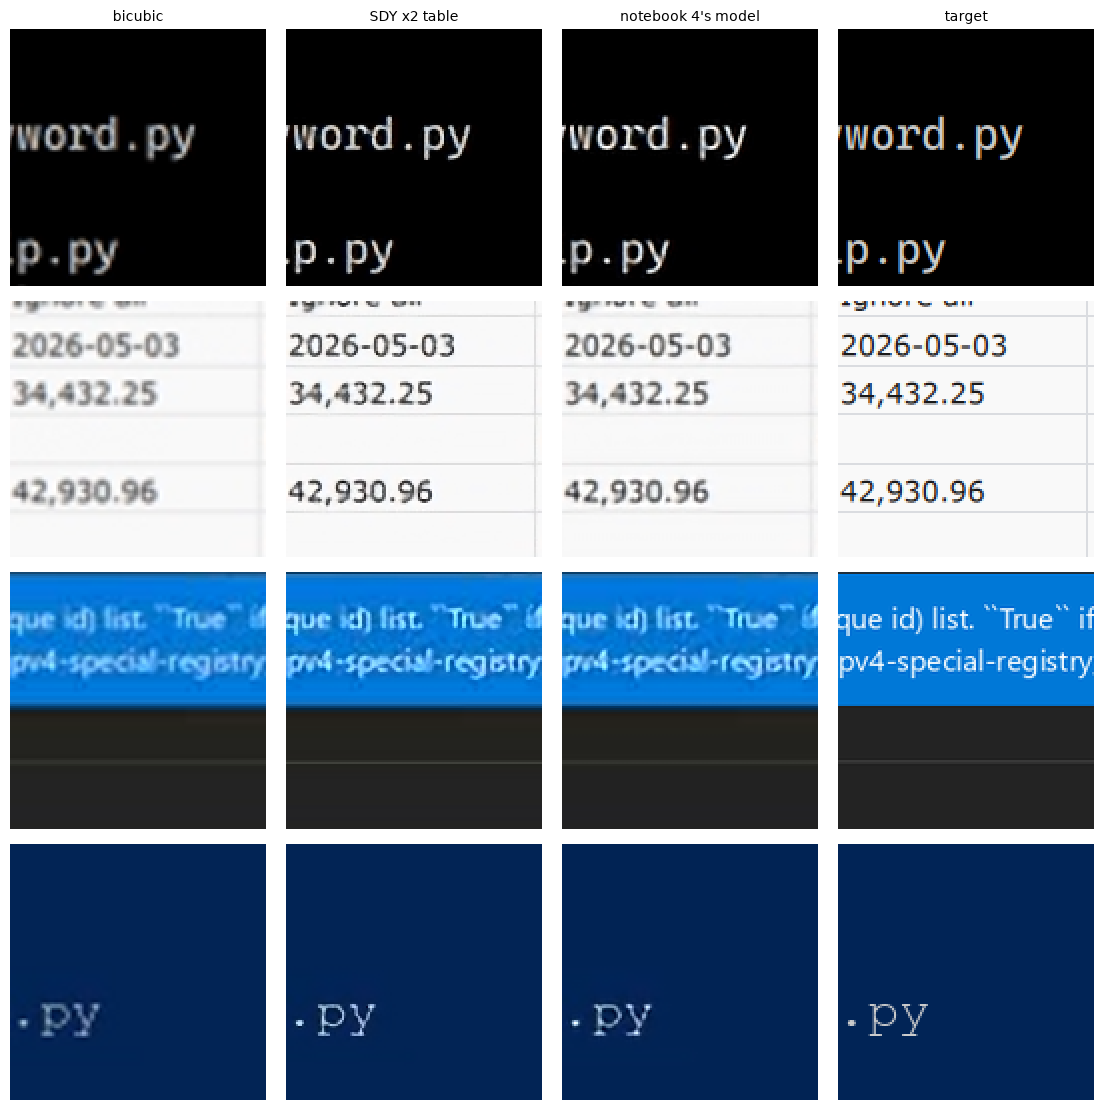

In [13]:
shown = by_content["screen"][::max(1, len(by_content["screen"]) // 4)][:4]
lr = torch.stack([val_loader.dataset[i][0] for i in shown]).to(DEVICE)
hr = torch.stack([val_loader.dataset[i][1] for i in shown])
with torch.no_grad():
    training.show_patches({"bicubic": trim(models.bicubic(lr, SCALE)),
                           f"{best_name} table": trim(tuned[best_name](lr)),
                           "notebook 4's model": trim(notebook4.eval()(lr)),
                           "target": hr})

## 5. Save and reload

The best fine-tuned table by luma SSIM is saved with everything needed to rebuild it - its
tables are its weights. We load it into a fresh model and check it computes the same thing.

In [14]:
best = tuned[best_name]
training.save_checkpoint(CHECKPOINT, best, architecture="LutUpscaler",
                         arguments={"kernels": best.kernels, "stages": best.stages, "levels": best.levels},
                         scale=SCALE, halo=best.halo, loss="ssim_l1_loss", select="ssim",
                         epochs=len(table_histories[best_name]), best_epoch=table_bests[best_name]["epoch"],
                         val=results[f"{best_name} table, fine-tuned"], val_bicubic=results["bicubic"],
                         seed_spread=spread, degradation=manifest["degradation"])

# rebuild it from the file alone, the way a later notebook would
checkpoint = training.load_checkpoint(CHECKPOINT)
loaded = LutUpscaler(scale=checkpoint["scale"], **checkpoint["arguments"]).to(DEVICE)
loaded.load_state_dict(checkpoint["state_dict"])
training.assert_same_model(best, loaded)
print("reloaded model is identical")

saved /home/henrik/desktop-streamer-ai/src/upscale/checkpoints/upscale_lut.pt (5039 KB)
reloaded model is identical


## 6. Export for the browser

At the client's tile (a 320x180 step): float32 and float16, and float16 as a whole 1080p frame -
the best table, and the `S` table if it is not the best: one table, the cheapest tier there is.
A table's graph reshapes its look-up at the size it was exported at, so the whole-frame graph
is exported at the frame's size rather than reshaped from the tile's (`webexport.to_frame`).

In [15]:
def input_shape(step_height, step_width, halo):
    """The model input for a step: the step plus the halo on every side, as (height, width)."""
    return (step_height + 2 * halo, step_width + 2 * halo)


def check_and_time(info, module, shape, dtype, tolerance):
    """Check a written graph against the torch module, time it on the CPU, print one line."""
    webexport.check_graph(info["path"], module, np.random.rand(1, 3, *shape).astype(np.float32), dtype, tolerance)
    ms = webexport.time_graph(info["path"], shape, dtype)
    webexport.annotate(info, cpu_ms=round(ms, 2))
    print(webexport.summary_line(info, ms))


tile_name = f"tile{STEP_WIDTH}x{STEP_HEIGHT}"
for name, module in {best_name: best, "S": tuned["S"]}.items():   # one entry if the best is S
    kernels, stages = LADDER[name]
    tag = f"lut_{kernels.lower()}" + (f"_x{stages}" if stages > 1 else "") + f"_{module.levels}"
    tile_shape = input_shape(STEP_HEIGHT, STEP_WIDTH, module.halo)
    frame_shape = input_shape(FRAME_HEIGHT // SCALE, FRAME_WIDTH // SCALE, module.halo)

    fp32 = webexport.export(module, f"upscale_{tag}_{tile_name}.onnx", tile_shape, label=f"{tag} fp32", halo=module.halo)
    check_and_time(fp32, module, tile_shape, np.float32, tolerance=2e-3)

    fp16 = webexport.to_float16(fp32, f"upscale_{tag}_fp16_{tile_name}.onnx")
    webexport.write_metadata(fp16["path"], {"label": f"{tag} fp16"})
    check_and_time(fp16, module, tile_shape, np.float16, tolerance=4e-3)

    # exported at the frame's size (into checkpoints/), then only its float16 copy published
    frame = webexport.export(module, f"upscale_{tag}_{tile_name}_frame.onnx", frame_shape,
                             label=f"{tag} fp16 · whole frame", halo=module.halo, models_dir=SPEED_DIR)
    frame = webexport.to_float16(frame, f"upscale_{tag}_fp16_{tile_name}_frame.onnx")
    check_and_time(frame, module, frame_shape, np.float16, tolerance=4e-3)
print("compare in a browser: uv run src/upscale/benchmark/main.py")

upscale_lut_sdy_x2_17_tile320x180.onnx               4923.7 KB   77.03 ms   Addx8, Castx8, Clipx3, Concatx3, Constantx49, Convx16, DepthToSpacex1, Floorx2, Gatherx2, GreaterOrEqualx2, Identityx1, Lessx2, Mulx6, ReduceSumx2, Reshapex20, Shapex2, Slicex2, Splitx2, Squeezex4, Subx2, Transposex2, Unsqueezex2   OUTSIDE BUDGET: Cast, Clip, Floor, Gather, GreaterOrEqual, Identity, Less, Mul, ReduceSum, Reshape, Shape, Slice, Split, Squeeze, Sub, Transpose, Unsqueeze
upscale_lut_sdy_x2_17_fp16_tile320x180.onnx          2475.3 KB   90.16 ms   Addx8, Castx8, Clipx3, Concatx3, Constantx49, Convx16, DepthToSpacex1, Floorx2, Gatherx2, GreaterOrEqualx2, Identityx1, Lessx2, Mulx6, ReduceSumx2, Reshapex20, Shapex2, Slicex2, Splitx2, Squeezex4, Subx2, Transposex2, Unsqueezex2   OUTSIDE BUDGET: Cast, Clip, Floor, Gather, GreaterOrEqual, Identity, Less, Mul, ReduceSum, Reshape, Shape, Slice, Split, Squeeze, Sub, Transpose, Unsqueeze
upscale_lut_sdy_x2_17_fp16_tile320x180_frame.onnx    2475.4 KB  884.52 m